
# Desafio 1 — Análise de Crédito | CredAIR

## 1. Entendimento do problema

O objetivo deste projeto é investigar os fatores associados à inadimplência em propostas de crédito e desenvolver um modelo de classificação utilizando Regressão Logística.

A variável resposta é `inadimplente`, que indica se uma proposta resultou ou não em inadimplência.

O problema será tratado como aprendizado supervisionado de classificação binária, pois os dados históricos possuem a resposta conhecida para cada registro.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#%pip install seaborn
import seaborn as sns

In [3]:
df = pd.read_csv("dataset.csv")
df

,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,2911.82,14,690,5934.19,60,Viagem,1,0
1,49,RR,Ensino Médio,3176.43,5,676,6791.38,24,Outros,2,0
2,48,AL,Ensino Superior,3429.40,23,558,14666.78,24,Outros,5,1
3,59,GO,Ensino Fundamental,10096.70,2,739,19053.24,24,Reforma,0,0
4,37,RJ,Ensino Fundamental,3033.25,24,797,6171.31,6,Educação,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4995,31,PB,Ensino Médio,3374.04,8,677,10198.45,24,Outros,2,0
4996,64,AM,Ensino Superior,3638.91,20,643,15374.40,24,Reforma,1,0
4997,48,MT,Ensino Médio,2211.31,21,486,8236.10,48,Saúde,0,1
4998,19,AP,Ensino Superior,14709.61,4,766,10617.90,18,Veículo,1,0


In [23]:
display(df.describe().T)#Transpose

,count,mean,std,min,25%,50%,75%,max
idade,5000.0,47.767400,31.646099,18.00,32.00,46.00,61.0000,750.00
renda_mensal,5000.0,5228.633582,3968.478198,100.00,2697.32,4146.30,6458.8775,44814.19
tempo_emprego_anos,5000.0,12.662200,7.517539,1.00,6.00,13.00,19.0000,74.00
score_credito,5000.0,652.481200,84.817076,335.00,594.00,653.00,710.0000,850.00
valor_solicitado,5000.0,14264.657378,8268.261465,1721.48,8467.17,12365.63,17764.8850,50000.00
prazo_meses,5000.0,29.922000,15.482515,6.00,18.00,24.00,36.0000,60.00
dividas_ativas,5000.0,1.900400,1.864719,0.00,0.00,1.00,3.0000,7.00
inadimplente,5000.0,0.344000,0.475089,0.00,0.00,0.00,1.0000,1.00


In [16]:
print("Valores ausentes por coluna:")
print(df.isna().sum())

print("\nQuantidade de linhas duplicadas:")
print(df.duplicated().sum())

Valores ausentes por coluna:
idade                 0
estado                0
escolaridade          0
renda_mensal          0
tempo_emprego_anos    0
score_credito         0
valor_solicitado      0
prazo_meses           0
finalidade            0
dividas_ativas        0
inadimplente          0
dtype: int64

Quantidade de linhas duplicadas:
19


In [17]:
print("Idades acima de 100:")
display(df[df["idade"] > 100])

print("Tempo de emprego acima de 40 anos:")
display(df[df["tempo_emprego_anos"] > 40])

print("Estados distintos:")
print(sorted(df["estado"].unique()))

Idades acima de 100:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
482,660,CE,Ensino Superior,8737.57,7,626,11238.42,24,Saúde,1,0
697,680,RN,Ensino Médio,12067.28,20,535,8190.12,12,Educação,1,0
925,710,RS,Ensino Superior,2785.13,15,658,31054.95,18,Educação,0,0
975,430,TO,Ensino Superior,1883.08,10,598,21313.88,12,Veículo,4,1
987,300,SC,Ensino Médio,4748.00,19,655,10309.08,36,Viagem,0,0
1220,360,AC,Ensino Médio,4863.25,4,764,7974.62,18,Viagem,0,0
1263,440,DF,Ensino Superior,4330.45,18,542,34623.38,48,Educação,2,1
1290,280,RS,Ensino Médio,4146.73,5,534,23719.54,6,Reforma,0,1
1507,500,MT,Ensino Superior,2493.59,2,758,15382.55,18,Educação,0,0
2671,340,SC,Ensino Médio,12069.75,8,683,11191.93,48,Reforma,4,0


Tempo de emprego acima de 40 anos:


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
388,56,RR,Ensino Médio,16193.38,57,617,7028.37,48,Reforma,0,0
850,62,PA,Ensino Fundamental,3741.96,63,730,12445.89,6,Veículo,1,1
1937,73,DF,Ensino Fundamental,2609.94,74,721,13972.16,36,Reforma,0,0
2659,45,RJ,Ensino Superior,2797.80,46,690,7981.42,48,Outros,1,0
2711,56,BA,Ensino Médio,2109.55,57,598,19541.27,36,Reforma,1,1
3162,64,MS,Ensino Médio,1996.15,65,597,15080.16,24,Veículo,1,0
4655,66,SP,Ensino Médio,2391.84,67,718,19779.15,24,Outros,2,1


Estados distintos:
['  AC ', '  AL ', '  AL  ', '  AM ', '  CE ', '  DF ', '  GO ', '  MG ', '  MS ', '  PA ', '  PB ', '  PB  ', '  PE  ', '  PI ', '  RO  ', '  RR ', '  RR  ', '  RS ', '  RS  ', '  SE ', '  SE  ', '  SP ', '  SP  ', ' AC  ', ' AL ', ' AM ', ' AM  ', ' AP  ', ' BA ', ' CE ', ' DF ', ' ES ', ' GO ', ' GO  ', ' MA ', ' MG ', ' MG  ', ' MS ', ' MT  ', ' PA ', ' PB ', ' PB  ', ' PE ', ' PE  ', ' PI ', ' PI  ', ' RJ ', ' RJ  ', ' RN ', ' RN  ', ' RO ', ' RR ', ' RR  ', ' SC ', ' SC  ', ' SE ', ' SE  ', ' TO ', 'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


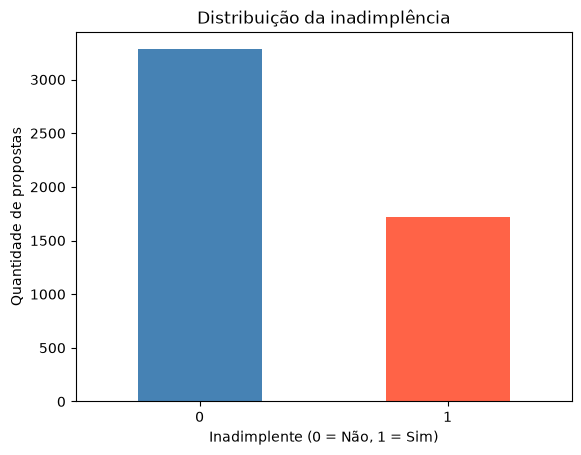

In [4]:
df["inadimplente"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)

plt.title("Distribuição da inadimplência")
plt.xlabel("Inadimplente (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade de propostas")
plt.xticks(rotation=0)
plt.show()

In [11]:
faixas_score = pd.cut(
    df["score_credito"],
    bins=[0, 500, 600, 700, 800, 1000],
    right=False
)

taxa_score = (
    df.groupby(faixas_score, observed=False)["inadimplente"]
      .agg(["count", "mean"])
)

taxa_score["mean"] = taxa_score["mean"] * 100

display(taxa_score.rename(columns={
    "count": "quantidade",
    "mean": "taxa_inadimplencia_%"
}))

,quantidade,taxa_inadimplencia_%
score_credito,,
"[0, 500)",188,63.829787
"[500, 600)",1163,51.590714
"[600, 700)",2174,34.222631
"[700, 800)",1255,18.486056
"[800, 1000)",220,10.909091


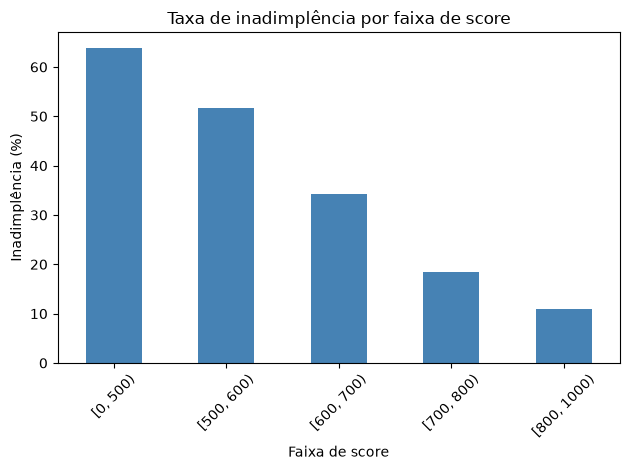

In [8]:
taxa_score["mean"].plot(kind="bar", color="steelblue")

plt.title("Taxa de inadimplência por faixa de score")
plt.xlabel("Faixa de score")
plt.ylabel("Inadimplência (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# Taxa de inadimplência por quantidade de dívidas
display(
    df.groupby("dividas_ativas")["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
      .assign(taxa_inadimplencia=lambda x: x["taxa_inadimplencia"] * 100)
      .round(2)
)

taxa_dividas = (
    df.groupby("dividas_ativas")["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_dividas["taxa_inadimplencia"] *= 100

display(taxa_dividas.round(2))

# Estatísticas financeiras por classe
display(
    df.groupby("inadimplente")[
        ["renda_mensal", "valor_solicitado", "prazo_meses"]
    ].mean().round(2)
)

,quantidade,taxa_inadimplencia
dividas_ativas,,
0,1554,27.41
1,965,26.84
2,848,36.32
3,631,38.67
4,420,46.19
5,322,45.65
6,162,51.23
7,98,60.20


,quantidade,taxa_inadimplencia
dividas_ativas,,
0,1554,27.41
1,965,26.84
2,848,36.32
3,631,38.67
4,420,46.19
5,322,45.65
6,162,51.23
7,98,60.20


,renda_mensal,valor_solicitado,prazo_meses
inadimplente,,,
0,5770.95,13404.56,31.05
1,4194.45,15904.85,27.77


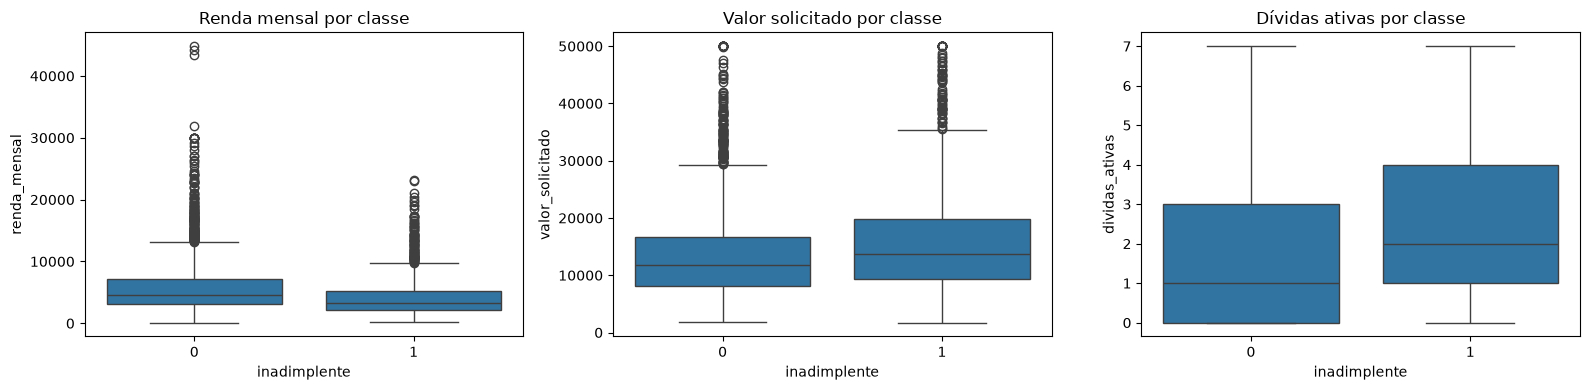

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=df, x="inadimplente", y="renda_mensal", ax=axes[0])
axes[0].set_title("Renda mensal por classe")

sns.boxplot(data=df, x="inadimplente", y="valor_solicitado", ax=axes[1])
axes[1].set_title("Valor solicitado por classe")

sns.boxplot(data=df, x="inadimplente", y="dividas_ativas", ax=axes[2])
axes[2].set_title("Dívidas ativas por classe")

# sns.boxplot(data=df, x="inadimplente", y="idade", ax=axes[3])
# axes[3].set_title("Dívidas ativas por Idade")

plt.tight_layout()
plt.show()

### Análise das distribuições por classe

Os boxplots indicam diferenças nas distribuições de renda mensal, valor solicitado e quantidade de dívidas ativas entre as classes de inadimplência. Os solicitantes inadimplentes aparentam apresentar menor renda mediana, maior valor mediano de empréstimo solicitado e maior quantidade mediana de dívidas ativas. Também foram observadas diversas observações potencialmente atípicas nas variáveis financeiras. Esses resultados são exploratórios e sugerem associações que deverão ser investigadas nas próximas etapas, sem permitir conclusões causais.

In [34]:
df["faixa_renda"] = pd.cut(
    df["renda_mensal"],
    bins=[0, 2000, 4000, 6000, 10000, float("inf")],
    labels=[
        "Até 2 mil",
        "2 a 4 mil",
        "4 a 6 mil",
        "6 a 10 mil",
        "Acima de 10 mil"
    ]
)

taxa_renda = (
    df.groupby("faixa_renda", observed=False)["inadimplente"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "quantidade",
          "mean": "taxa_inadimplencia"
      })
)

taxa_renda["taxa_inadimplencia"] *= 100

display(taxa_renda.round(2))

,quantidade,taxa_inadimplencia
faixa_renda,,
Até 2 mil,639,54.62
2 a 4 mil,1766,40.15
4 a 6 mil,1188,28.96
6 a 10 mil,924,24.46
Acima de 10 mil,483,19.05


### Análise da inadimplência por dívidas ativas e renda

A análise da taxa de inadimplência por quantidade de dívidas ativas revelou uma tendência geral de aumento da inadimplência em grupos com maior número de dívidas. A taxa variou de 26,84% entre solicitantes com uma dívida para 60,20% entre aqueles com sete dívidas ativas.

Em relação à renda mensal, observou-se uma associação inversa entre a faixa de renda e a taxa de inadimplência. O grupo com renda de até R$ 2.000 apresentou taxa de 54,62%, enquanto o grupo com renda superior a R$ 10.000 apresentou taxa de 19,05%.

Esses resultados sugerem que a quantidade de dívidas ativas e a renda mensal são variáveis relevantes para investigar o risco de inadimplência. Entretanto, as associações observadas não demonstram causalidade e deverão ser avaliadas em conjunto com as demais variáveis e com os resultados do modelo preditivo.